# 07 — Monte Carlo noise and the zero-loss floor

The campaign response is log10 of a Jeffreys-corrected Monte Carlo proportion. A sample with
0 losses in N encounters enters as log10(0.5 / (N + 1)) (-5.3 at N = 1e5), and `sim.py` hands
the GP no standard error (it treats every sample as exact). Known truth: log10 p(x) linear in x,
tau = -3. Two surfaces: a gentle one whose floor is far from tau, a steep one whose floor starts
just past tau. Compared: the GP fitted as exact vs with the delta-method standard error.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mvlse import Continuous, DesignSpace, fit_surrogate

N = 100_000                       # encounters per sample (config.N_ENCOUNTERS)
TAU = -3.0
FLOOR = np.log10(0.5 / (N + 1))
space = DesignSpace({"x": Continuous(0.0, 1.0)})
x_train = np.linspace(0.0, 1.0, 12)
x_grid = np.linspace(0.0, 1.0, 1001)
w_train = space.encode([{"x": v} for v in x_train])
w_grid = space.encode([{"x": v} for v in x_grid])
SURFACES = {"gentle": lambda x: -1.0 - 6.0 * x,     # tau at x = 1/3, floor reached near x = 0.72
            "steep": lambda x: -1.0 - 12.0 * x}     # tau at x = 1/6, floor reached near x = 0.36


def mc_log10_p(log10_p, rng):
    """blueskycdarr.blackbox.log10_p_los on a simulated binomial count."""
    k = rng.binomial(N, 10.0 ** log10_p)
    p_hat = (k + 0.5) / (N + 1.0)
    se = np.sqrt(p_hat * (1 - p_hat) / N) / (p_hat * np.log(10.0))
    return np.log10(p_hat), se, k


def crossing(mu):
    """First x where the prediction crosses tau (the estimated boundary)."""
    i = np.flatnonzero(np.diff(np.sign(mu - TAU)) != 0)
    return x_grid[i[0]] if len(i) else np.nan

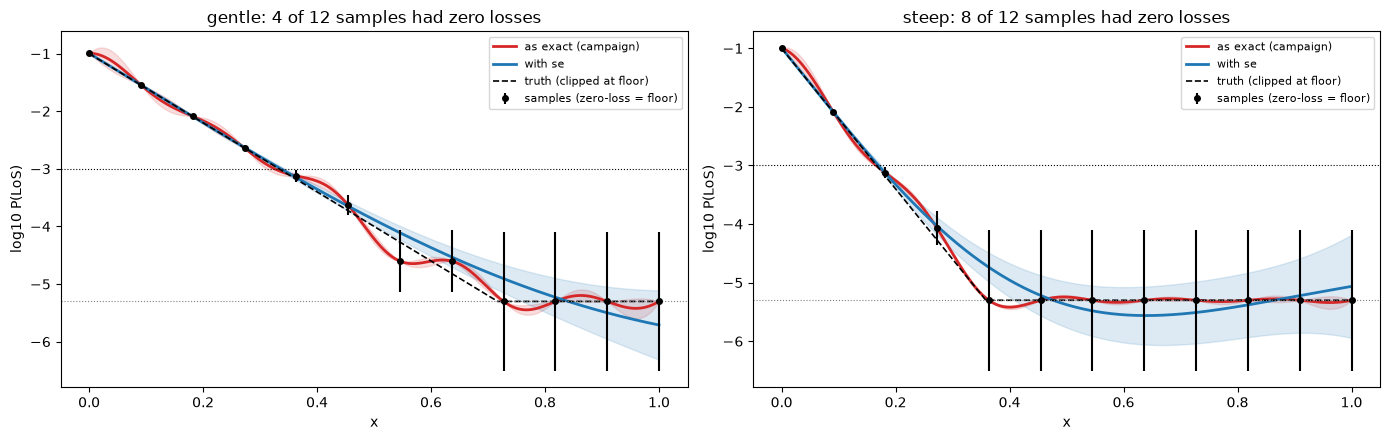

,surface,fit,true boundary,estimated,sd at true boundary,max overshoot above floor region [dec]
0,gentle,as exact (campaign),0.3333,0.325,0.0342,0.1037
1,gentle,with se,0.3333,0.336,0.0211,0.1286
2,steep,as exact (campaign),0.1667,0.166,0.0127,0.0245
3,steep,with se,0.1667,0.169,0.0275,0.2367


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
rows = []
for ax, (name, truth) in zip(axes, SURFACES.items()):
    x_true = (-1.0 - TAU) / (-truth(1.0) - 1.0)  # where truth = tau
    y, se, k = mc_log10_p(truth(x_train), np.random.default_rng(0))
    exact = fit_surrogate("hs_dim", space, w_train, y, rng=np.random.default_rng(0))
    noisy = fit_surrogate("hs_dim", space, w_train, y, se, rng=np.random.default_rng(0))
    for label, model, c in (("as exact (campaign)", exact, "C3"), ("with se", noisy, "C0")):
        mu, sd = model.predict(w_grid)
        ax.fill_between(x_grid, mu - 1.96 * sd, mu + 1.96 * sd, color=c, alpha=0.15)
        ax.plot(x_grid, mu, color=c, lw=2, label=label)
        rows.append({"surface": name, "fit": label, "true boundary": x_true, "estimated": crossing(mu),
                     "sd at true boundary": float(np.interp(x_true, x_grid, sd)),
                     "max overshoot above floor region [dec]": float(mu[x_grid > 0.8].max() - FLOOR)})
    ax.plot(x_grid, np.maximum(truth(x_grid), FLOOR), "k--", lw=1.2, label="truth (clipped at floor)")
    ax.errorbar(x_train, y, yerr=1.96 * se, fmt="ko", ms=4, label="samples (zero-loss = floor)")
    ax.axhline(TAU, color="k", lw=0.8, ls=":"); ax.axhline(FLOOR, color="grey", lw=0.8, ls=":")
    ax.set_title(f"{name}: {int((k == 0).sum())} of {len(k)} samples had zero losses")
    ax.set_xlabel("x"); ax.set_ylabel("log10 P(LoS)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(4)

In [4]:
# Boundary error over 50 Monte Carlo replications of the training data.
rows = []
for name, truth in SURFACES.items():
    x_true = (-1.0 - TAU) / (-truth(1.0) - 1.0)
    err = {"as exact (campaign)": [], "with se": []}
    for rep in range(50):
        y, se, _ = mc_log10_p(truth(x_train), np.random.default_rng(100 + rep))
        for label, s in (("as exact (campaign)", None), ("with se", se)):
            mu, _ = fit_surrogate("hs_dim", space, w_train, y, s, rng=np.random.default_rng(rep)).predict(w_grid)
            err[label].append(crossing(mu) - x_true)
    for label, e in err.items():
        e = np.array(e)
        rows.append({"surface": name, "fit": label, "mean error": np.nanmean(e),
                     "RMS error": np.sqrt(np.nanmean(e ** 2)), "worst |error|": np.nanmax(np.abs(e))})
pd.DataFrame(rows).round(4)

,surface,fit,mean error,RMS error,worst |error|
0,gentle,as exact (campaign),-0.0047,0.0090,0.0283
1,gentle,with se,-0.0003,0.0050,0.0123
2,steep,as exact (campaign),-0.0036,0.0086,0.0247
3,steep,with se,-0.0008,0.0030,0.0067
